This notebook calculates the three theoretical visibility curves required for the lab:

1. **Single star**
2. **Binary, parallel baseline**
3. **Binary, 45° baseline**

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import j1

# Experimental parameters
source_distance_m = 21.81
wavelength_nm = 630.0

single_star_diameter_mm = 2.0
binary_component_diameter_mm = 1.0
binary_separation_mm = 2.0
binary_angles_deg = {"Parallel": 0.0, "45 degrees": 45.0}

baselines_mm = np.array([2.0, 4.0, 5.0, 6.0, 8.0, 10.0, 15.0])
baseline_grid_mm = np.linspace(0.0, 18.0, 1200)

wavelength_m = wavelength_nm * 1e-9
single_star_diameter_m = single_star_diameter_mm * 1e-3
binary_component_diameter_m = binary_component_diameter_mm * 1e-3
binary_separation_m = binary_separation_mm * 1e-3
baselines_m = baselines_mm * 1e-3
baseline_grid_m = baseline_grid_mm * 1e-3

print(f"Source distance: {source_distance_m:.2f} m")
print(f"Central wavelength: {wavelength_nm:.1f} nm")
print(f"Baselines: {baselines_mm} mm")

Source distance: 21.81 m
Central wavelength: 630.0 nm
Baselines: [ 2.  4.  5.  6.  8. 10. 15.] mm


For a uniform circular source of physical diameter $d$ at distance $L$, the angular diameter is

$$
\theta \simeq \frac{d}{L}.
$$

Its signed visibility is

$$
\mu(B)=\frac{2J_1(x)}{x},\qquad x=\frac{\pi B\theta}{\lambda}.
$$

For two equal uniform disks, the signed visibility is the single-component envelope multiplied by the binary modulation:

$$
\mu(B,\psi)=\frac{2J_1(x_*)}{x_*}
\cos\!\left(\frac{\pi B\theta_s\cos\psi}{\lambda}\right),
$$

where $\theta_*$ is the angular diameter of one component, $\theta_s$ is the angular separation, and $\psi$ is the angle between the baseline and the binary separation. The measured fringe contrast is $V=|\mu|$. A negative signed value indicates a $\pi$ phase shift (bright and dark fringes are exchanged).


In [67]:
def besinc(x):
    """Return 2*J1(x)/x, with the limiting value 1 at x=0."""
    x = np.asarray(x, dtype=float)
    y = np.ones_like(x)
    mask = np.abs(x) > 1e-12
    y[mask] = 2.0 * j1(x[mask]) / x[mask]
    return y


def disk_visibility(baseline_m, angular_diameter_rad):
    """Signed visibility of a uniform circular disk."""
    x = np.pi * np.asarray(baseline_m) * angular_diameter_rad / wavelength_m
    return besinc(x)


def binary_visibility(baseline_m, component_diameter_rad,
                       separation_rad, angle_deg):
    """Signed visibility of two equal uniform disks."""
    baseline_m = np.asarray(baseline_m, dtype=float)
    angle_rad = np.deg2rad(angle_deg)
    envelope = besinc(np.pi * baseline_m * component_diameter_rad / wavelength_m)
    phase = np.pi * baseline_m * separation_rad * np.cos(angle_rad) / wavelength_m
    return envelope * np.cos(phase)

theta_single = single_star_diameter_m / source_distance_m
theta_component = binary_component_diameter_m / source_distance_m
theta_separation = binary_separation_m / source_distance_m
rad_to_arcsec = 206265.0

print(f"Single-star angular diameter: {theta_single * rad_to_arcsec:.3f} arcsec")
print(f"Binary component angular diameter: {theta_component * rad_to_arcsec:.3f} arcsec")
print(f"Binary angular separation: {theta_separation * rad_to_arcsec:.3f} arcsec")

Single-star angular diameter: 18.915 arcsec
Binary component angular diameter: 9.457 arcsec
Binary angular separation: 18.915 arcsec


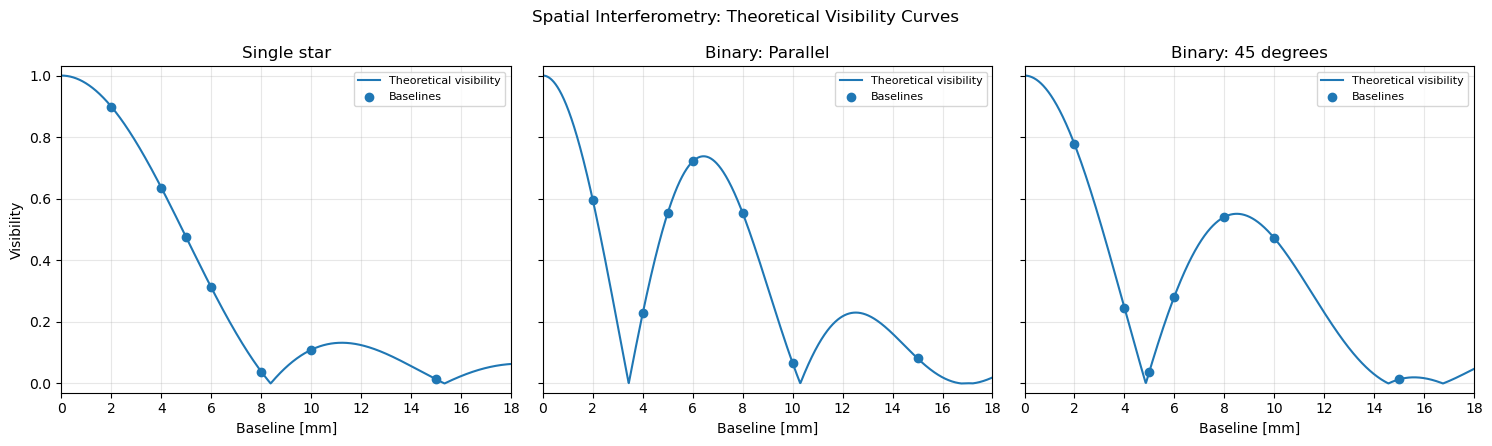

Saved: spatial_interferometry_visibility_curves.png


In [69]:
curves = {
    "Single star": np.abs(disk_visibility(baseline_grid_m, theta_single)),
}
points = {
    "Single star": np.abs(disk_visibility(baselines_m, theta_single)),
}

for label, angle in binary_angles_deg.items():
    curves[f"Binary: {label}"] = np.abs(
        binary_visibility(baseline_grid_m, theta_component, theta_separation, angle)
    )
    points[f"Binary: {label}"] = np.abs(
        binary_visibility(baselines_m, theta_component, theta_separation, angle)
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (label, curve) in zip(axes, curves.items()):
    ax.plot(baseline_grid_mm, curve, label="Theoretical visibility")
    ax.scatter(baselines_mm, points[label], zorder=3,
               label="Baselines")
    ax.set(title=label, xlabel="Baseline [mm]", xlim=(0, baseline_grid_mm.max()), ylim=(-0.03, 1.03))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Visibility")
fig.suptitle("Spatial Interferometry: Theoretical Visibility Curves")
fig.tight_layout()
fig.savefig("spatial_interferometry_visibility_curves.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: spatial_interferometry_visibility_curves.png")

In [71]:
results = pd.DataFrame({"Baseline [mm]": baselines_mm})
for label, value in points.items():
    results[f"{label} |μ|" ] = value

display(results.round(3))
results.to_csv("spatial_interferometry_visibility_values.csv", index=False,
               float_format="%.8f")

print("Saved: spatial_interferometry_visibility_values.csv")

,Baseline [mm],Single star |μ|,Binary: Parallel |μ|,Binary: 45 degrees |μ|
0,2.0,0.899,0.594,0.777
1,4.0,0.636,0.230,0.246
2,5.0,0.474,0.555,0.039
3,6.0,0.312,0.721,0.282
4,8.0,0.039,0.553,0.541
5,10.0,0.109,0.066,0.472
6,15.0,0.014,0.082,0.013


Saved: spatial_interferometry_visibility_values.csv
